# 06. Evaluación mediante K-Fold 5 y 10

El objetivo es evaluar la estabilidad del modelo 1D-CNN con diferentes particiones de los datos, siguiendo la evaluación K-Fold (K = 5 y K = 10) que reporta el artículo semilla (Honi y Szathmary, 2024). Se hacen dos evaluaciones: la **reproducción aproximada del escenario del artículo**, con los 1025 registros, y un **análisis adicional** con los 302 registros sin duplicados. Es una evaluación basada en el procedimiento descrito por el artículo, no una réplica exacta.

## 1. Configuración

Se definen los parámetros del experimento y se indica cuáles provienen del artículo y cuáles son decisiones del proyecto.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)

sns.set_theme(style="whitegrid")
tf.config.experimental.enable_op_determinism()   # para que el entrenamiento sea reproducible

RUTA = "../data/heart.csv"
SEMILLA = 42
EPOCAS = 150
BATCH_SIZE = 32
LEARNING_RATE = 0.001
UMBRAL = 0.5

n_registros, n_columnas = pd.read_csv(RUTA).shape

configuracion = pd.DataFrame([
    ("Dataset", RUTA, "Artículo (UCI Heart Disease, 1025 pacientes)"),
    ("Registros", n_registros, "Artículo"),
    ("Variables predictoras", n_columnas - 1, "Artículo"),
    ("Variable objetivo", "target (0 = ausencia, 1 = presencia)", "Artículo"),
    ("Validación cruzada", "K-Fold con K = 5 y K = 10", "Artículo"),
    ("Arquitectura", "1D-CNN de la Figura 7 (igual que los Experimentos A y B)", "Artículo, con decisiones del proyecto (padding)"),
    ("Escalado", "MinMaxScaler [0, 1], ajustado dentro de cada fold", "Artículo (rango); ajuste por fold: decisión del proyecto"),
    ("Épocas", EPOCAS, "Artículo"),
    ("Optimizador", "Adam", "Decisión del proyecto"),
    ("Learning rate", LEARNING_RATE, "Decisión del proyecto"),
    ("Función de pérdida", "binary_crossentropy", "Decisión del proyecto"),
    ("Batch size", BATCH_SIZE, "Decisión del proyecto"),
    ("Tipo de K-Fold", "Estratificado, con mezcla previa", "Decisión del proyecto"),
    ("Semilla", f"{SEMILLA} (en cada fold: {SEMILLA} + número de fold)", "Decisión del proyecto"),
    ("Umbral de clasificación", UMBRAL, "Decisión del proyecto"),
    ("Validación interna (validation_split)", "No se usa: el fold de validación solo se usa para evaluar", "Decisión del proyecto"),
], columns=["Parámetro", "Valor", "Fuente"])

print("TensorFlow:", tf.__version__)
configuracion

TensorFlow: 2.21.0


,Parámetro,Valor,Fuente
0,Dataset,../data/heart.csv,"Artículo (UCI Heart Disease, 1025 pacientes)"
1,Registros,1025,Artículo
2,Variables predictoras,13,Artículo
3,Variable objetivo,"target (0 = ausencia, 1 = presencia)",Artículo
4,Validación cruzada,K-Fold con K = 5 y K = 10,Artículo
5,Arquitectura,1D-CNN de la Figura 7 (igual que los Experimen...,"Artículo, con decisiones del proyecto (padding)"
6,Escalado,"MinMaxScaler [0, 1], ajustado dentro de cada fold",Artículo (rango); ajuste por fold: decisión de...
7,Épocas,150,Artículo
8,Optimizador,Adam,Decisión del proyecto
9,Learning rate,0.001,Decisión del proyecto


**Interpretación del resultado**

Del artículo provienen el dataset (1025 pacientes, 13 variables predictoras y `target`), el uso de K-Fold con K = 5 y K = 10, el escalado a [0, 1] y las 150 épocas. **Son decisiones del proyecto**: Adam, learning rate 0.001, `binary_crossentropy`, batch size 32, semilla, umbral 0.5 y el uso de K-Fold estratificado. Además, dentro de cada fold no se usa `validation_split`: el fold de validación solo se usa para evaluar. Esto difiere de los Experimentos A y B y se anota porque el artículo no detalla cómo validó durante el entrenamiento.

## 2. Arquitectura

Se define una función que construye la misma arquitectura de los Experimentos A y B. Se llamará una vez por fold para obtener un modelo nuevo.

In [2]:
def construir_modelo():
    modelo = tf.keras.Sequential([
        layers.Input(shape=(13, 1)),

        layers.Conv1D(32, 2, padding="valid", activation="sigmoid"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),

        layers.Conv1D(64, 2, padding="valid", activation="sigmoid"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
        layers.BatchNormalization(),

        layers.Conv1D(128, 2, padding="valid", activation="sigmoid"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(200, activation="relu"),
        layers.Dropout(0.1),
        layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return modelo

PARAMETROS_EXPERIMENTOS_A_B = 285873

modelo_prueba = construir_modelo()
modelo_prueba.summary()
print("Parámetros de los Experimentos A y B:", f"{PARAMETROS_EXPERIMENTOS_A_B:,}")
print("Parámetros de este modelo:           ", f"{modelo_prueba.count_params():,}")
assert modelo_prueba.count_params() == PARAMETROS_EXPERIMENTOS_A_B, "La arquitectura no coincide"
print("La arquitectura coincide con los Experimentos A y B")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 12, 32)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 11, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 11, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 128)        │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 9, 128)         │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       230,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 285,873 (1.09 MB)

 Trainable params: 285,169 (1.09 MB)

 Non-trainable params: 704 (2.75 KB)

Parámetros de los Experimentos A y B: 285,873
Parámetros de este modelo:            285,873
La arquitectura coincide con los Experimentos A y B


**Interpretación del resultado**

El modelo construido tiene 285,873 parámetros, los mismos de los Experimentos A y B, y la verificación de coincidencia pasó sin errores. Las formas de las capas son las ya conocidas: (12, 32), (11, 64), (10, 128) y (9, 128) en las convoluciones y 1152 valores tras el Flatten. La arquitectura es la misma en todos los folds y en ambos datasets, así que las diferencias de resultados no se deben a cambios de modelo.

## 3. Carga del dataset

Se carga `heart.csv` en memoria y se revisan sus dimensiones, el objetivo, los valores faltantes y los duplicados. El archivo no se modifica.

In [3]:
df = pd.read_csv(RUTA)
X = df.drop(columns="target")
y = df["target"]

print("Dimensiones:", df.shape)
print("Columnas:", list(df.columns))
print("target:", y.value_counts().sort_index().to_dict())
print("Valores faltantes:", int(df.isnull().sum().sum()))
print("Duplicados exactos:", int(df.duplicated().sum()))
print("Filas distintas:", len(df.drop_duplicates()))
print("X:", X.shape, "| y:", y.shape)

Dimensiones: (1025, 14)
Columnas: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
target: {0: 499, 1: 526}
Valores faltantes: 0
Duplicados exactos: 723
Filas distintas: 302
X: (1025, 13) | y: (1025,)


**Interpretación del resultado**

El dataset tiene 1025 registros y 14 columnas, sin valores faltantes. Hay 723 duplicados exactos y 302 filas distintas. El `target` está casi equilibrado, con 499 registros de la clase 0 y 526 de la clase 1. Son los mismos datos y las mismas cifras de los notebooks anteriores.

## 4. Procedimiento de K-Fold sobre los 1025 registros originales

Se define el procedimiento de cada fold y se muestran los tamaños de las particiones antes de entrenar. Aquí se conservan los 1025 registros, incluidos los duplicados.

In [4]:
METRICAS = ["Accuracy", "Precision", "Recall", "F1", "Especificidad", "AUC"]

def calcular_metricas(y_real, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred),
        "F1": f1_score(y_real, y_pred),
        "Especificidad": tn / (tn + fp),
        "AUC": roc_auc_score(y_real, y_prob),
    }

def evaluar_kfold(X, y, k, nombre_dataset):
    # Para cada fold: escalador nuevo ajustado solo con el train del fold, modelo nuevo, evaluación solo en el fold de validación
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEMILLA)
    filas_completas = np.column_stack([X.values, y.values])
    resultados, modelos, indices_validacion = [], [], []

    for fold, (idx_tr, idx_va) in enumerate(skf.split(X, y), start=1):
        inicio = time.time()
        X_tr, X_va = X.iloc[idx_tr], X.iloc[idx_va]
        y_tr, y_va = y.iloc[idx_tr], y.iloc[idx_va]

        escalador = MinMaxScaler().fit(X_tr)                       # solo con el train del fold
        escalador_ok = bool(escalador.n_samples_seen_ == len(X_tr)
                            and np.allclose(escalador.data_min_, X_tr.min().values)
                            and np.allclose(escalador.data_max_, X_tr.max().values))
        X_tr_c = escalador.transform(X_tr).reshape(-1, 13, 1).astype("float32")
        X_va_c = escalador.transform(X_va).reshape(-1, 13, 1).astype("float32")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEMILLA + fold)
        modelo = construir_modelo()                                # modelo nuevo desde cero
        modelos.append(modelo)
        iteraciones_iniciales = int(modelo.optimizer.iterations.numpy())

        historial = modelo.fit(X_tr_c, y_tr.values, epochs=EPOCAS, batch_size=BATCH_SIZE, verbose=0)

        y_prob = modelo.predict(X_va_c, verbose=0).ravel()
        y_pred = (y_prob >= UMBRAL).astype(int)

        filas_train = set(map(tuple, filas_completas[idx_tr]))
        copias = sum(tuple(f) in filas_train for f in filas_completas[idx_va])

        fila = {"Dataset": nombre_dataset, "K": k, "Fold": fold,
                "N_train": len(X_tr), "N_validacion": len(X_va)}
        fila.update(calcular_metricas(y_va.values, y_pred, y_prob))
        fila.update({
            "Accuracy_train_final": historial.history["accuracy"][-1],
            "Val_con_copia_en_train": copias,
            "Escalador_solo_train": escalador_ok,
            "Modelo_nuevo": iteraciones_iniciales == 0,
            "Epocas_entrenadas": len(historial.history["loss"]),
            "Tiempo_s": time.time() - inicio,
        })
        resultados.append(fila)
        indices_validacion.append(idx_va)

    df_res = pd.DataFrame(resultados)
    cada_registro_una_vez = bool(np.array_equal(np.sort(np.concatenate(indices_validacion)), np.arange(len(X))))
    modelos_distintos = len({id(m) for m in modelos}) == k
    return df_res, cada_registro_una_vez, modelos_distintos

# Vista previa de las particiones (sin entrenar)
for k in (5, 10):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEMILLA)
    tamanos = [(len(a), len(b), int(y.iloc[b].sum())) for a, b in skf.split(X, y)]
    print(f"K = {k}: (train, validación, positivos en validación) por fold:")
    print("  ", tamanos)
    print("   Cada registro aparece en validación exactamente una vez:",
          np.array_equal(np.sort(np.concatenate([b for _, b in skf.split(X, y)])), np.arange(len(X))))

K = 5: (train, validación, positivos en validación) por fold:
   [(820, 205, 105), (820, 205, 105), (820, 205, 105), (820, 205, 105), (820, 205, 106)]
   Cada registro aparece en validación exactamente una vez: True
K = 10: (train, validación, positivos en validación) por fold:
   [(922, 103, 53), (922, 103, 53), (922, 103, 53), (922, 103, 53), (922, 103, 53), (923, 102, 52), (923, 102, 52), (923, 102, 52), (923, 102, 52), (923, 102, 53)]
   Cada registro aparece en validación exactamente una vez: True


**Interpretación del resultado**

Con K = 5 cada fold tiene 820 registros de entrenamiento y 205 de validación (105 o 106 positivos). Con K = 10 son 922 o 923 de entrenamiento y 102 o 103 de validación (52 o 53 positivos). La estratificación mantiene la proporción de clases en cada fold, y en ambos casos cada registro aparece en validación exactamente una vez. Todavía no se ha entrenado nada.

## 5. Métricas

Se calculan seis métricas por fold y luego la media, la desviación estándar, el mínimo y el máximo. Antes se comprueba la función de métricas con un ejemplo pequeño de resultado conocido.

In [5]:
def resumir(df_res):
    filas = []
    for m in METRICAS:
        filas.append({"Métrica": m, "Media": df_res[m].mean(), "Desv_estandar": df_res[m].std(ddof=1),
                      "Minimo": df_res[m].min(), "Maximo": df_res[m].max()})
    return pd.DataFrame(filas)

def tabla_folds(df_res):
    t = df_res[["Fold"] + METRICAS].copy().set_index("Fold")
    return (t * 100).round(2)

def tabla_resumen(df_res):
    r = resumir(df_res).set_index("Métrica")
    return (r * 100).round(2).rename(columns={"Media": "Media (%)", "Desv_estandar": "Desv. estándar (pp)",
                                               "Minimo": "Mínimo (%)", "Maximo": "Máximo (%)"})

# Comprobación con un ejemplo de 8 casos: TN = 3, FP = 1, FN = 1, TP = 3
y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1])
y_pred_ej = np.array([0, 0, 0, 1, 1, 1, 1, 0])
y_prob_ej = np.array([0.1, 0.2, 0.3, 0.6, 0.9, 0.8, 0.7, 0.4])
m = calcular_metricas(y_real, y_pred_ej, y_prob_ej)
print({k: round(v, 4) for k, v in m.items()})
assert all(abs(m[k] - 0.75) < 1e-9 for k in ["Accuracy", "Precision", "Recall", "F1", "Especificidad"])
assert abs(m["AUC"] - 15 / 16) < 1e-9
print("La función de métricas devuelve los valores esperados (AUC esperado = 15/16 = 0.9375)")

{'Accuracy': 0.75, 'Precision': 0.75, 'Recall': 0.75, 'F1': 0.75, 'Especificidad': np.float64(0.75), 'AUC': np.float64(0.9375)}
La función de métricas devuelve los valores esperados (AUC esperado = 15/16 = 0.9375)


**Interpretación del resultado**

La función de métricas devolvió los valores esperados en el ejemplo de 8 casos: 0.75 en accuracy, precision, recall, F1 y especificidad, y 0.9375 (15/16) en AUC. Esto confirma que las fórmulas están bien implementadas antes de aplicarlas a los folds. La desviación estándar se calcula con n - 1 (muestral), por lo que con pocos folds es una estimación gruesa de la variabilidad.

## 6. K-Fold = 5 sobre los 1025 registros

Se entrenan 5 modelos independientes, uno por fold, y se evalúa cada uno sobre su fold de validación.

Folds ejecutados: 5 | épocas por fold: [150]
Escalador ajustado solo con el train del fold, en todos los folds: True
Modelo nuevo (optimizador en 0 iteraciones) en todos los folds: True
Objetos de modelo distintos entre folds: True
Cada registro validado exactamente una vez: True
Registros train + validación por fold: [1025]
Filas de validación con copia exacta en el train del fold: [205, 202, 205, 201, 202] (total 1015 de 1025)
Tiempo total: 332.5 s

Métricas por fold (%):


,Accuracy,Precision,Recall,F1,Especificidad,AUC
Fold,,,,,,
1,100.00,100.00,100.00,100.00,100.00,100.00
2,99.02,98.13,100.00,99.06,98.00,99.94
3,100.00,100.00,100.00,100.00,100.00,100.00
4,98.05,100.00,96.19,98.06,100.00,99.58
5,99.02,98.15,100.00,99.07,97.98,100.00


Resumen entre folds:


,Media (%),Desv. estándar (pp),Mínimo (%),Máximo (%)
Métrica,,,,
Accuracy,99.22,0.82,98.05,100.0
Precision,99.26,1.02,98.13,100.0
Recall,99.24,1.70,96.19,100.0
F1,99.24,0.81,98.06,100.0
Especificidad,99.20,1.10,97.98,100.0
AUC,99.90,0.18,99.58,100.0


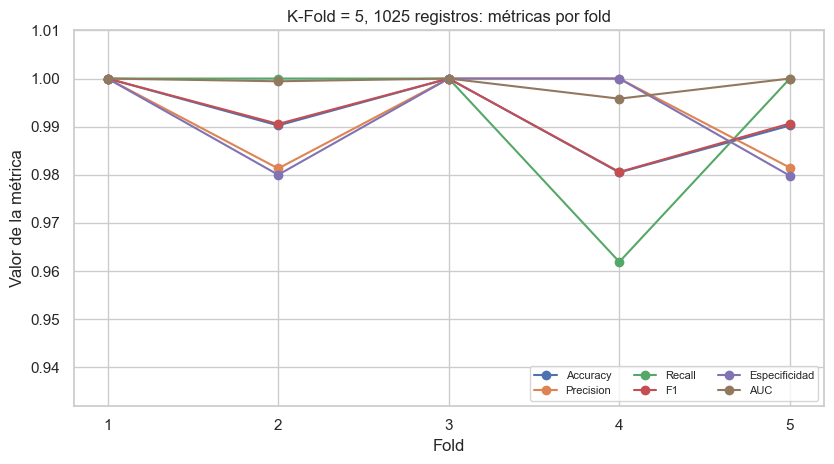

In [6]:
def grafica_folds(df_res, k, archivo, titulo):
    plt.figure(figsize=(8.5, 4.8))
    for m in METRICAS:
        plt.plot(df_res["Fold"], df_res[m], marker="o", label=m)
    plt.title(titulo)
    plt.xlabel("Fold")
    plt.ylabel("Valor de la métrica")
    plt.xticks(df_res["Fold"])
    plt.ylim(max(0, df_res[METRICAS].min().min() - 0.03), 1.01)
    plt.legend(ncol=3, loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()

def verificar(df_res, cada_vez, distintos, k):
    print("Folds ejecutados:", len(df_res), "| épocas por fold:", sorted(df_res["Epocas_entrenadas"].unique().tolist()))
    print("Escalador ajustado solo con el train del fold, en todos los folds:", bool(df_res["Escalador_solo_train"].all()))
    print("Modelo nuevo (optimizador en 0 iteraciones) en todos los folds:", bool(df_res["Modelo_nuevo"].all()))
    print("Objetos de modelo distintos entre folds:", distintos)
    print("Cada registro validado exactamente una vez:", cada_vez)
    print("Registros train + validación por fold:", sorted((df_res["N_train"] + df_res["N_validacion"]).unique().tolist()))
    print("Filas de validación con copia exacta en el train del fold:", df_res["Val_con_copia_en_train"].tolist(),
          "(total {} de {})".format(df_res["Val_con_copia_en_train"].sum(), df_res["N_validacion"].sum()))
    print("Tiempo total: {:.1f} s".format(df_res["Tiempo_s"].sum()))

res_orig_5, ok_orig_5, dist_orig_5 = evaluar_kfold(X, y, 5, "Original")
verificar(res_orig_5, ok_orig_5, dist_orig_5, 5)
print()
print("Métricas por fold (%):")
display(tabla_folds(res_orig_5))
print("Resumen entre folds:")
display(tabla_resumen(res_orig_5))
grafica_folds(res_orig_5, 5, "../resultados/figuras/kfold_5_metricas.png", "K-Fold = 5, 1025 registros: métricas por fold")

**Interpretación del resultado**

Los 5 folds se entrenaron 150 épocas cada uno, con un escalador y un modelo nuevos en cada fold, y cada registro se validó una vez. La accuracy media es 99.22 % con desviación 0.82 pp, entre 98.05 % y 100 %; el fold más débil es el 4, con recall de 96.19 %. Pero 1015 de los 1025 registros de validación (99.0 %) tenían una copia exacta en el entrenamiento de su fold, por lo que estos valores no miden bien la generalización a pacientes nuevos. El entrenamiento tardó 332.5 s.

## 7. K-Fold = 10 sobre los 1025 registros

Se repite exactamente el mismo procedimiento con 10 folds.

Folds ejecutados: 10 | épocas por fold: [150]
Escalador ajustado solo con el train del fold, en todos los folds: True
Modelo nuevo (optimizador en 0 iteraciones) en todos los folds: True
Objetos de modelo distintos entre folds: True
Cada registro validado exactamente una vez: True
Registros train + validación por fold: [1025]
Filas de validación con copia exacta en el train del fold: [103, 103, 103, 103, 103, 102, 102, 102, 102, 102] (total 1025 de 1025)
Tiempo total: 673.3 s

Métricas por fold (%):


,Accuracy,Precision,Recall,F1,Especificidad,AUC
Fold,,,,,,
1,99.03,100.0,98.11,99.05,100.0,100.0
2,100.00,100.0,100.00,100.00,100.0,100.0
3,100.00,100.0,100.00,100.00,100.0,100.0
4,100.00,100.0,100.00,100.00,100.0,100.0
5,100.00,100.0,100.00,100.00,100.0,100.0
6,100.00,100.0,100.00,100.00,100.0,100.0
7,98.04,96.3,100.00,98.11,96.0,100.0
8,100.00,100.0,100.00,100.00,100.0,100.0
9,100.00,100.0,100.00,100.00,100.0,100.0


Resumen entre folds:


,Media (%),Desv. estándar (pp),Mínimo (%),Máximo (%)
Métrica,,,,
Accuracy,99.71,0.66,98.04,100.0
Precision,99.63,1.17,96.30,100.0
Recall,99.81,0.60,98.11,100.0
F1,99.72,0.64,98.11,100.0
Especificidad,99.60,1.26,96.00,100.0
AUC,100.00,0.00,100.00,100.0


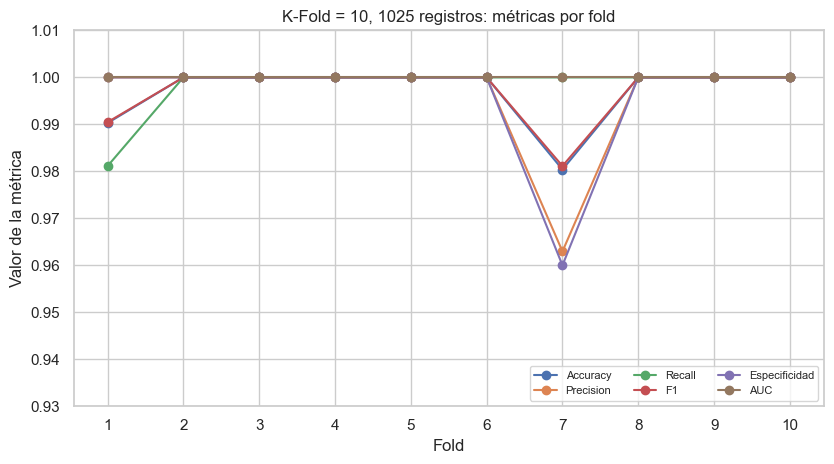

In [7]:
res_orig_10, ok_orig_10, dist_orig_10 = evaluar_kfold(X, y, 10, "Original")
verificar(res_orig_10, ok_orig_10, dist_orig_10, 10)
print()
print("Métricas por fold (%):")
display(tabla_folds(res_orig_10))
print("Resumen entre folds:")
display(tabla_resumen(res_orig_10))
grafica_folds(res_orig_10, 10, "../resultados/figuras/kfold_10_metricas.png", "K-Fold = 10, 1025 registros: métricas por fold")

**Interpretación del resultado**

Los 10 folds también usaron escalador y modelo nuevos, y se entrenaron 150 épocas cada uno. La accuracy media es 99.71 % con desviación 0.66 pp: 8 de los 10 folds llegan a 100 % y los más bajos son el fold 7 (98.04 %) y el fold 1 (99.03 %). Las 1025 filas de validación (100 %) tenían una copia exacta en el entrenamiento, y el AUC es 100.00 % en todos los folds (a dos decimales). Un resultado tan perfecto es coherente con que el modelo haya visto esos mismos casos. El entrenamiento tardó 673.3 s.

## 8. Comparación entre K = 5 y K = 10

Se comparan la media y la desviación estándar de cada métrica para ver cuál configuración varía menos entre folds.

In [8]:
r5 = resumir(res_orig_5).set_index("Métrica")
r10 = resumir(res_orig_10).set_index("Métrica")

comparacion_k = pd.DataFrame({
    "K=5 media (%)": r5["Media"] * 100,
    "K=5 desviación (pp)": r5["Desv_estandar"] * 100,
    "K=10 media (%)": r10["Media"] * 100,
    "K=10 desviación (pp)": r10["Desv_estandar"] * 100,
}).round(2)

print("Desviación estándar muestral (ddof = 1). Con K = 5 se calcula sobre 5 valores y con K = 10 sobre 10.")
print("Métricas con menor desviación en K = 5:", comparacion_k.index[comparacion_k["K=5 desviación (pp)"] < comparacion_k["K=10 desviación (pp)"]].tolist())
print("Métricas con menor desviación en K = 10:", comparacion_k.index[comparacion_k["K=10 desviación (pp)"] < comparacion_k["K=5 desviación (pp)"]].tolist())
comparacion_k

Desviación estándar muestral (ddof = 1). Con K = 5 se calcula sobre 5 valores y con K = 10 sobre 10.
Métricas con menor desviación en K = 5: ['Precision', 'Especificidad']
Métricas con menor desviación en K = 10: ['Accuracy', 'Recall', 'F1', 'AUC']


,K=5 media (%),K=5 desviación (pp),K=10 media (%),K=10 desviación (pp)
Métrica,,,,
Accuracy,99.22,0.82,99.71,0.66
Precision,99.26,1.02,99.63,1.17
Recall,99.24,1.70,99.81,0.60
F1,99.24,0.81,99.72,0.64
Especificidad,99.20,1.10,99.60,1.26
AUC,99.90,0.18,100.00,0.00


**Interpretación del resultado**

K = 10 tiene la media algo mayor (accuracy 99.71 % frente a 99.22 %) y menor desviación en accuracy, recall, F1 y AUC, mientras que K = 5 tiene menor desviación en precision y especificidad. No hay una configuración claramente menos variable: las diferencias son de pocas décimas o de alrededor de 1 pp, y la desviación de K = 5 se calcula con solo 5 valores. Además, con K = 10 cada modelo entrena con más datos (922 frente a 820) y casi todas las filas de validación tienen copia en el entrenamiento. No se declara a ninguna de las dos mejor por tener mayor accuracy.

## 9. Comparación con el artículo

Se compara la accuracy de los K-Fold del proyecto con la reportada por el artículo, tomando como referencia la Tabla 4 y la sección 4.2.

In [9]:
articulo = {5: {"Accuracy": 98.53, "Precision": 99.0, "Recall": 99.92, "F1": 99.91},
            10: {"Accuracy": 99.12, "Precision": 99.94, "Recall": 99.93, "F1": 99.98}}

filas = []
for k, res in ((5, res_orig_5), (10, res_orig_10)):
    media = res["Accuracy"].mean() * 100
    desv = res["Accuracy"].std(ddof=1) * 100
    filas.append((f"K-Fold {k}", f"{articulo[k]['Accuracy']:.2f} %", f"{media:.2f} % (desv. {desv:.2f} pp)",
                  f"{media - articulo[k]['Accuracy']:+.2f} pp"))
tabla_art = pd.DataFrame(filas, columns=["Experimento", "Artículo", "Nuestro resultado (media)", "Diferencia (nuestro - artículo)"])
print(tabla_art.to_string(index=False))

print()
print("Otras métricas (media de nuestros folds frente a la Tabla 4 del artículo):")
filas = []
for k, res in ((5, res_orig_5), (10, res_orig_10)):
    for m in ["Precision", "Recall", "F1"]:
        filas.append((f"K-Fold {k}", m, f"{articulo[k][m]:.2f} %", f"{res[m].mean() * 100:.2f} %"))
print(pd.DataFrame(filas, columns=["Experimento", "Métrica", "Artículo", "Nuestro resultado"]).to_string(index=False))
print()
print("Nota: las Conclusiones del artículo intercambian los valores (99.12 % para K = 5 y 98.53 % para K = 10).")
print("Aquí se usa como referencia la Tabla 4 y la sección 4.2; el artículo no se corrige.")

Experimento Artículo Nuestro resultado (media) Diferencia (nuestro - artículo)
   K-Fold 5  98.53 %   99.22 % (desv. 0.82 pp)                        +0.69 pp
  K-Fold 10  99.12 %   99.71 % (desv. 0.66 pp)                        +0.59 pp

Otras métricas (media de nuestros folds frente a la Tabla 4 del artículo):
Experimento   Métrica Artículo Nuestro resultado
   K-Fold 5 Precision  99.00 %           99.26 %
   K-Fold 5    Recall  99.92 %           99.24 %
   K-Fold 5        F1  99.91 %           99.24 %
  K-Fold 10 Precision  99.94 %           99.63 %
  K-Fold 10    Recall  99.93 %           99.81 %
  K-Fold 10        F1  99.98 %           99.72 %

Nota: las Conclusiones del artículo intercambian los valores (99.12 % para K = 5 y 98.53 % para K = 10).
Aquí se usa como referencia la Tabla 4 y la sección 4.2; el artículo no se corrige.


**Interpretación del resultado**

La accuracy media del proyecto es 99.22 % para K = 5 y 99.71 % para K = 10, frente a 98.53 % y 99.12 % de la Tabla 4 del artículo (+0.69 y +0.59 pp). En recall y F1 de K = 5 nuestros valores son menores que los del artículo (99.24 % frente a 99.92 % y 99.24 % frente a 99.91 %), y en precision son algo mayores. Con los valores que dan las Conclusiones, intercambiados, las diferencias serían +0.10 y +1.18 pp. Como en ambos escenarios casi todas las filas de validación tienen copia en el entrenamiento y hay diferencias de procedimiento, no puede decirse que el modelo supere al artículo; solo que los órdenes de magnitud son similares.

## 10. Análisis adicional: K-Fold sin duplicados

Se eliminan los duplicados exactos solo en memoria (1025 a 302 registros) y se repiten K = 5 y K = 10 con la misma arquitectura, los mismos hiperparámetros y el escalado dentro de cada fold.

In [10]:
df_sin_dup = df.drop_duplicates().copy()
X_sd = df_sin_dup.drop(columns="target")
y_sd = df_sin_dup["target"]

print("Registros originales:", len(df), "| duplicados eliminados:", len(df) - len(df_sin_dup),
      "| registros únicos:", len(df_sin_dup))
print("target:", y_sd.value_counts().sort_index().to_dict())
print("df original sigue con", len(df), "filas")
print()

res_sd_5, ok_sd_5, dist_sd_5 = evaluar_kfold(X_sd, y_sd, 5, "Sin duplicados")
print("K = 5, sin duplicados")
verificar(res_sd_5, ok_sd_5, dist_sd_5, 5)
display(tabla_folds(res_sd_5))
display(tabla_resumen(res_sd_5))
print()

res_sd_10, ok_sd_10, dist_sd_10 = evaluar_kfold(X_sd, y_sd, 10, "Sin duplicados")
print("K = 10, sin duplicados")
verificar(res_sd_10, ok_sd_10, dist_sd_10, 10)
display(tabla_folds(res_sd_10))
display(tabla_resumen(res_sd_10))

Registros originales: 1025 | duplicados eliminados: 723 | registros únicos: 302
target: {0: 138, 1: 164}
df original sigue con 1025 filas



K = 5, sin duplicados
Folds ejecutados: 5 | épocas por fold: [150]
Escalador ajustado solo con el train del fold, en todos los folds: True
Modelo nuevo (optimizador en 0 iteraciones) en todos los folds: True
Objetos de modelo distintos entre folds: True
Cada registro validado exactamente una vez: True
Registros train + validación por fold: [302]
Filas de validación con copia exacta en el train del fold: [0, 0, 0, 0, 0] (total 0 de 302)
Tiempo total: 169.5 s


,Accuracy,Precision,Recall,F1,Especificidad,AUC
Fold,,,,,,
1,81.97,86.67,78.79,82.54,85.71,86.96
2,83.61,82.86,87.88,85.29,78.57,86.90
3,73.33,73.53,78.12,75.76,67.86,78.63
4,81.67,84.38,81.82,83.08,81.48,87.99
5,76.67,75.68,84.85,80.00,66.67,85.63


,Media (%),Desv. estándar (pp),Mínimo (%),Máximo (%)
Métrica,,,,
Accuracy,79.45,4.29,73.33,83.61
Precision,80.62,5.71,73.53,86.67
Recall,82.29,4.11,78.12,87.88
F1,81.33,3.64,75.76,85.29
Especificidad,76.06,8.43,66.67,85.71
AUC,85.22,3.78,78.63,87.99


K = 10, sin duplicados
Folds ejecutados: 10 | épocas por fold: [150]
Escalador ajustado solo con el train del fold, en todos los folds: True
Modelo nuevo (optimizador en 0 iteraciones) en todos los folds: True
Objetos de modelo distintos entre folds: True
Cada registro validado exactamente una vez: True
Registros train + validación por fold: [302]
Filas de validación con copia exacta en el train del fold: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0] (total 0 de 302)
Tiempo total: 377.8 s


,Accuracy,Precision,Recall,F1,Especificidad,AUC
Fold,,,,,,
1,83.87,92.86,76.47,83.87,92.86,90.76
2,80.65,86.67,76.47,81.25,85.71,87.39
3,86.67,87.50,87.50,87.50,85.71,86.16
4,73.33,72.22,81.25,76.47,64.29,80.58
5,80.00,85.71,75.00,80.00,85.71,83.04
6,73.33,70.00,87.50,77.78,57.14,78.79
7,73.33,75.00,75.00,75.00,71.43,77.90
8,83.33,82.35,87.50,84.85,78.57,95.54
9,86.67,88.24,88.24,88.24,84.62,91.86


,Media (%),Desv. estándar (pp),Mínimo (%),Máximo (%)
Métrica,,,,
Accuracy,80.12,5.26,73.33,86.67
Precision,81.95,7.61,70.00,92.86
Recall,82.32,6.03,75.00,88.24
F1,81.83,4.52,75.00,88.24
Especificidad,77.53,11.47,57.14,92.86
AUC,85.75,5.82,77.90,95.54


**Interpretación del resultado**

Con 302 registros únicos (138 y 164 por clase) ninguna fila de validación tiene copia exacta en el entrenamiento de su fold (0 de 302), y las demás comprobaciones se cumplen igual. La accuracy media es 79.45 % con K = 5 (desviación 4.29 pp) y 80.12 % con K = 10 (5.26 pp); el AUC es 85.22 % y 85.75 %. La especificidad es la métrica más baja y más variable (76.06 ± 8.43 y 77.53 ± 11.47, con mínimo de 57.14 %). Estos valores son cercanos al 81.32 % del Experimento B, obtenido con una sola partición de 91 registros de prueba.

## 11. Comparación entre el dataset original y el dataset sin duplicados

Se reúnen los cuatro experimentos en una tabla y en una gráfica, y se guardan los resultados en `resultados/tablas`.

Media entre folds (%):


Métrica            Accuracy  Precision  Recall     F1  Especificidad     AUC
Dataset        K                                                            
Original       5      99.22      99.26   99.24  99.24          99.20   99.90
               10     99.71      99.63   99.81  99.72          99.60  100.00
Sin duplicados 5      79.45      80.62   82.29  81.33          76.06   85.22
               10     80.12      81.95   82.32  81.83          77.53   85.75

Desviación estándar entre folds (pp):


Métrica            Accuracy  Precision  Recall    F1  Especificidad   AUC
Dataset        K                                                         
Original       5       0.82       1.02    1.70  0.81           1.10  0.18
               10      0.66       1.17    0.60  0.64           1.26  0.00
Sin duplicados 5       4.29       5.71    4.11  3.64           8.43  3.78
               10      5.26       7.61    6.03  4.52          11.47  5.82

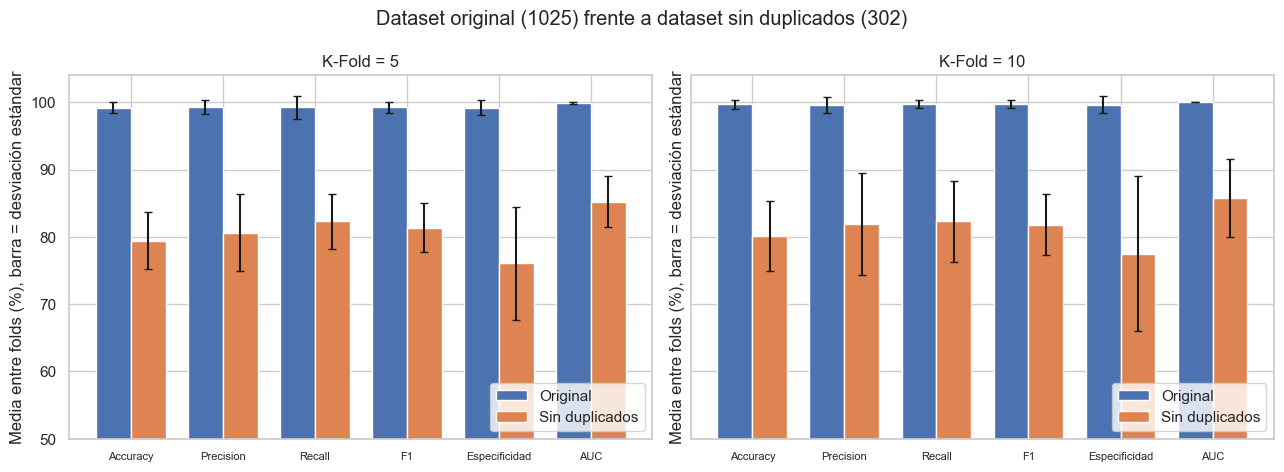

kfold_resultados.csv (30, 17)
kfold_resumen.csv (24, 7)
kfold_comparacion.csv (4, 15)


In [11]:
todos = pd.concat([res_orig_5, res_orig_10, res_sd_5, res_sd_10], ignore_index=True)
resumen_largo = []
for (dataset, k), grupo in todos.groupby(["Dataset", "K"], sort=False):
    for fila in resumir(grupo).to_dict("records"):
        resumen_largo.append({"Dataset": dataset, "K": k, **fila})
resumen_largo = pd.DataFrame(resumen_largo)

medias = resumen_largo.pivot_table(index=["Dataset", "K"], columns="Métrica", values="Media", sort=False)[METRICAS]
desvs = resumen_largo.pivot_table(index=["Dataset", "K"], columns="Métrica", values="Desv_estandar", sort=False)[METRICAS]

comparacion_final = medias.add_suffix("_media").join(desvs.add_suffix("_desv")).reset_index()
comparacion_final.insert(2, "Registros", comparacion_final["Dataset"].map({"Original": len(df), "Sin duplicados": len(df_sin_dup)}))

todos.round(6).to_csv("../resultados/tablas/kfold_resultados.csv", index=False)
resumen_largo.round(6).to_csv("../resultados/tablas/kfold_resumen.csv", index=False)
comparacion_final.round(6).to_csv("../resultados/tablas/kfold_comparacion.csv", index=False)

print("Media entre folds (%):")
display((medias * 100).round(2))
print("Desviación estándar entre folds (pp):")
display((desvs * 100).round(2))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ancho = 0.38
posiciones = np.arange(len(METRICAS))
for eje, k in zip(ejes, (5, 10)):
    for desplazamiento, dataset in ((-ancho / 2, "Original"), (ancho / 2, "Sin duplicados")):
        m = medias.loc[(dataset, k)] * 100
        d = desvs.loc[(dataset, k)] * 100
        eje.bar(posiciones + desplazamiento, m.values, ancho, yerr=d.values, capsize=3, label=dataset)
    eje.set_xticks(posiciones)
    eje.set_xticklabels(METRICAS, fontsize=8)
    eje.set_title(f"K-Fold = {k}")
    eje.set_ylim(50, 104)
    eje.set_ylabel("Media entre folds (%), barra = desviación estándar")
    eje.legend(loc="lower right")
fig.suptitle("Dataset original (1025) frente a dataset sin duplicados (302)")
plt.tight_layout()
plt.savefig("../resultados/figuras/comparacion_kfold_original_sin_duplicados.png", dpi=150)
plt.show()

for nombre in ["kfold_resultados.csv", "kfold_resumen.csv", "kfold_comparacion.csv"]:
    print(nombre, pd.read_csv("../resultados/tablas/" + nombre).shape)

**Interpretación del resultado**

Al eliminar los duplicados, la accuracy media baja unos 19.8 pp con K = 5 (de 99.22 % a 79.45 %) y unos 19.6 pp con K = 10 (de 99.71 % a 80.12 %), y el AUC baja unos 14.7 y 14.3 pp. La desviación entre folds también aumenta mucho: la de la accuracy pasa de 0.82 a 4.29 pp con K = 5 y de 0.66 a 5.26 pp con K = 10. La gráfica muestra la misma separación en las seis métricas y los dos valores de K. Los dos datasets difieren en el contenido de duplicados, pero también en el tamaño.

## 12. Interpretación

Al eliminar los duplicados, la accuracy media baja unos 20 pp (de 99.22 % a 79.45 % con K = 5 y de 99.71 % a 80.12 % con K = 10) y la variabilidad entre folds aumenta de menos de 1 pp a 4 o 5 pp, aunque parte de ese aumento podría deberse al menor tamaño de los folds. K = 5 y K = 10 dan resultados similares, con diferencias menores que la variabilidad entre folds. Los resultados sugieren que el dataset original está afectado por la duplicación, ya que entre el 99.0 % y el 100 % de las filas de validación tenían una copia exacta en el entrenamiento, pero los duplicados no son la única explicación posible: el dataset sin duplicados también es más pequeño y se usó una sola semilla.

## 13. Limitaciones

- El artículo tiene inconsistencias internas: sus Conclusiones intercambian los resultados de K = 5 y K = 10 respecto de la Tabla 4 y la sección 4.2, y su Figura 9 describe un esquema de 10 particiones con 80 % entrenamiento, 10 % prueba y 10 % validación, distinto del K-Fold estándar usado aquí.
- El artículo no especifica varios hiperparámetros (optimizador, learning rate, pérdida, batch size, padding, semilla); todos son decisiones del proyecto.
- El dataset contiene 723 duplicados exactos. En la evaluación con los 1025 registros, las copias exactas pueden quedar repartidas entre entrenamiento y validación de un mismo fold.
- La arquitectura del artículo presenta diferencias entre la Figura 7, la Tabla 2 y el texto; aquí se usó la de la Figura 7, igual que en los Experimentos A y B.
- Los resultados publicados por el artículo también presentan inconsistencias, documentadas en `resultados/auditoria/comparacion_articulo.md`.
- Cada configuración se ejecutó una sola vez con una sola semilla; no se midió la variabilidad entre repeticiones. Con 302 registros, cada fold de validación es pequeño (unos 60 con K = 5 y unos 30 con K = 10).
- Aquí no se usa validación interna dentro de cada fold, a diferencia de los Experimentos A y B, por lo que los resultados no son estrictamente comparables con ellos.

## 14. Conclusión

Con la evaluación basada en el procedimiento descrito por el artículo (reproducción aproximada del escenario K-Fold), el modelo alcanza una accuracy media de 99.22 % con K = 5 y de 99.71 % con K = 10 sobre los 1025 registros, valores del mismo orden que los del artículo (98.53 % y 99.12 %). Sin embargo, casi todas las filas de validación tienen una copia exacta en el entrenamiento, y al eliminar los duplicados la accuracy media baja a cerca de 80 %, con mucha más variación entre folds. K-Fold mostró así que el rendimiento alto depende de cómo se tratan los duplicados, algo que una sola partición no deja ver con tanta claridad. K = 5 y K = 10 dieron resultados similares. Esto no es una réplica exacta del artículo, y no se puede atribuir la caída únicamente a los duplicados, porque el dataset sin duplicados también es más pequeño.